# Turing Test Analysis — CV Maxing

Empirical evaluation of **CV Maxing** vs. **Human** vs. **ChatGPT** across 3 candidate profiles:
- **Case 1**: Tomás (Junior Data Scientist)
- **Case 2**: Pedro (Career Switcher — Fullstack)
- **Case 3**: Rita (Senior Tech Lead)

> **Sample**: $N = 11$ participants, $33$ case reviews, $99$ CV ratings. Fully anonymized (GDPR compliant).

In [1]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import pointbiserialr, spearmanr

# Filter specific NumPy/SciPy version mismatch warning if present
warnings.filterwarnings(
    "ignore",
    message="A NumPy version >=1.23.5 and <2.3.0 is required for this version of SciPy.*",
    category=UserWarning,
)

# Plot styling configuration: Modern, publication-quality aesthetic
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({
    "figure.dpi": 150,
    "font.sans-serif": ["Segoe UI", "DejaVu Sans", "Helvetica", "Arial"],
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "axes.labelsize": 10,
    "axes.labelweight": "medium",
    "xtick.labelsize": 9.5,
    "ytick.labelsize": 9.5,
    "legend.fontsize": 9,
    "legend.title_fontsize": 9.5,
    "axes.edgecolor": "#CCCCCC",
    "axes.linewidth": 0.8,
    "grid.color": "#E5E5E5",
    "grid.linestyle": ":",
    "grid.alpha": 0.7,
})

# Path resolution: works from repository root or turing/ directory
BASE_DIR: Path = Path.cwd()
if not (BASE_DIR / "turing").exists() and BASE_DIR.name != "turing":
    raise FileNotFoundError("Please execute the notebook from the repository root or the turing/ directory.")
if BASE_DIR.name == "turing":
    BASE_DIR = BASE_DIR.parent

DATA_DIR: Path = BASE_DIR / "turing" / "data"
csv_candidates: list[Path] = sorted(DATA_DIR.glob("*.csv"), key=lambda p: p.stat().st_mtime, reverse=True)
if not csv_candidates:
    raise FileNotFoundError(f"No CSV survey response files found in {DATA_DIR}")

CSV_PATH: Path = csv_candidates[0]
raw_df: pd.DataFrame = pd.read_csv(CSV_PATH)

print(f"Loaded survey dataset (GDPR compliant): {CSV_PATH.name}")
print(f"Total validated participants: {len(raw_df)}")
raw_df.head(3)

Loaded survey dataset (GDPR compliant): survey_responses_anonymized.csv
Total validated participants: 11


,participant_id,"AI Perception Rating: On a scale of 1 to 5, how AI-generated or human-written does each version appear? [Version A]","AI Perception Rating: On a scale of 1 to 5, how AI-generated or human-written does each version appear? [Version B]","AI Perception Rating: On a scale of 1 to 5, how AI-generated or human-written does each version appear? [Version C]","Case 1: Overall, which single version do you believe was tailored by a HUMAN?","Case 1: If you were the hiring manager, which version would you recommend for an interview?",Case 1: Briefly explain what details or phrasing led to your choices (Optional),"AI Perception Rating: On a scale of 1 to 5, how AI-generated or human-written does each version appear? [Version A].1","AI Perception Rating: On a scale of 1 to 5, how AI-generated or human-written does each version appear? [Version B].1","AI Perception Rating: On a scale of 1 to 5, how AI-generated or human-written does each version appear? [Version C].1","Case 2: Overall, which single version do you believe was tailored by a HUMAN?","Case 2: If you were the hiring manager, which version would you recommend for an interview?",Case 2: Briefly explain what details or phrasing led to your choices (Optional),"AI Perception Rating: On a scale of 1 to 5, how AI-generated or human-written does each version appear? [Version A].2","AI Perception Rating: On a scale of 1 to 5, how AI-generated or human-written does each version appear? [Version B].2","AI Perception Rating: On a scale of 1 to 5, how AI-generated or human-written does each version appear? [Version C].2","Case 3: Overall, which single version do you believe was tailored by a HUMAN?","Case 3: If you were the hiring manager, which version would you recommend for an interview?",Case 3: Briefly explain what details or phrasing led to your choices (Optional)
0,1,2 - Likely Human,3 - Uncertain,4 - Likely AI,Version A,Version B,NaN,3 - Uncertain,2 - Likely Human,2 - Likely Human,Version C,Version C,NaN,3 - Uncertain,3 - Uncertain,1 - Definitely Human,Version C,Version B,NaN
1,2,1 - Definitely Human,5 - Definitely AI,3 - Uncertain,Version A,Version B,NaN,3 - Uncertain,1 - Definitely Human,5 - Definitely AI,Version B,Version A,NaN,5 - Definitely AI,3 - Uncertain,1 - Definitely Human,Version C,Version B,NaN
2,3,4 - Likely AI,1 - Definitely Human,5 - Definitely AI,Version B,Version B,NaN,4 - Likely AI,2 - Likely Human,4 - Likely AI,Version B,Version B,NaN,3 - Uncertain,1 - Definitely Human,4 - Likely AI,Version B,Version B,NaN


## 1. Setup & Counterbalancing

**Likert Scale**: 1 = Human · 2 = Likely Human · 3 = Uncertain · 4 = Likely AI · 5 = AI

**Latin Square Mapping** (prevents position bias):

| Case | Version A | Version B | Version C |
| :--- | :--- | :--- | :--- |
| **Case 1 (Tomás)** | CV Maxing | ChatGPT | Human |
| **Case 2 (Pedro)** | Human | CV Maxing | ChatGPT |
| **Case 3 (Rita)** | ChatGPT | Human | CV Maxing |

In [2]:
from typing import Any

LIKERT_MAPPING: dict[str, int] = {
    "1 - Definitely Human": 1,
    "2 - Likely Human": 2,
    "3 - Uncertain": 3,
    "4 - Likely AI": 4,
    "5 - Definitely AI": 5,
}

CASE_COUNTERBALANCE: dict[int, dict[str, str]] = {
    1: {"A": "CV Maxing", "B": "ChatGPT", "C": "Human"},
    2: {"A": "Human", "B": "CV Maxing", "C": "ChatGPT"},
    3: {"A": "ChatGPT", "B": "Human", "C": "CV Maxing"},
}

CASE_LABELS: dict[int, str] = {
    1: "Case 1 — Tomás (Junior)",
    2: "Case 2 — Pedro (Transition)",
    3: "Case 3 — Rita (Senior)",
}

CONDITION_ORDER: list[str] = ["Human", "CV Maxing", "ChatGPT"]
CONDITION_PALETTE: dict[str, str] = {
    "Human": "#10B981",       # Vibrant Emerald Green
    "CV Maxing": "#2563EB",   # Vibrant Royal Blue
    "ChatGPT": "#EF4444",     # Vibrant Crimson Red
}


def find_matching_columns(df: pd.DataFrame, pattern: str) -> list[str]:
    # Dynamically discover column names matching a case-insensitive pattern
    matches = [col for col in df.columns if pattern.lower() in str(col).lower()]
    if not matches:
        raise KeyError(f"Expected column pattern not found in DataFrame: '{pattern}'")
    return matches


# Discover rating, human choice, and interview recommendation columns
rating_cols: dict[int, list[str]] = {
    case: find_matching_columns(raw_df, "AI Perception Rating")[
        (case - 1) * 3 : (case - 1) * 3 + 3
    ]
    for case in range(1, 4)
}

human_cols: dict[int, str] = {}
interview_cols: dict[int, str] = {}

for case in range(1, 4):
    human_candidates = [
        col for col in raw_df.columns
        if f"Case {case}:" in str(col) and "HUMAN" in str(col).upper()
    ]
    interview_candidates = [
        col for col in raw_df.columns
        if f"Case {case}:" in str(col) and "hiring manager" in str(col).lower()
    ]
    if not human_candidates or not interview_candidates:
        raise KeyError(f"Survey choice columns not found for Case {case}")
    human_cols[case] = human_candidates[0]
    interview_cols[case] = interview_candidates[0]


def build_tidy_survey_dataframe(df: pd.DataFrame) -> pd.DataFrame:
    # Transform raw wide Google Forms responses into a normalized, tidy long-format DataFrame
    records: list[dict[str, Any]] = []

    for _, row in df.iterrows():
        # Use existing participant_id or increment
        p_id = int(row["participant_id"]) if "participant_id" in row and pd.notna(row["participant_id"]) else len(records) // 9 + 1

        for case in range(1, 4):
            # Extract Likert ratings for versions A, B, C
            version_ratings: dict[str, float] = {}
            for offset, letter in enumerate(["A", "B", "C"]):
                raw_val = row[rating_cols[case][offset]]
                version_ratings[letter] = LIKERT_MAPPING.get(str(raw_val).strip(), np.nan)

            # Extract selected version letters
            human_raw = str(row[human_cols[case]]).replace("Version ", "").strip() if pd.notna(row[human_cols[case]]) else np.nan
            interview_raw = str(row[interview_cols[case]]).replace("Version ", "").strip() if pd.notna(row[interview_cols[case]]) else np.nan

            human_choice = CASE_COUNTERBALANCE[case].get(human_raw, np.nan)
            interview_choice = CASE_COUNTERBALANCE[case].get(interview_raw, np.nan)

            for letter, condition in CASE_COUNTERBALANCE[case].items():
                records.append({
                    "respondent_id": p_id,
                    "case_id": case,
                    "case_name": CASE_LABELS[case],
                    "version_letter": letter,
                    "condition": condition,
                    "ai_rating": version_ratings[letter],
                    "selected_human": human_choice,
                    "selected_interview": interview_choice,
                    "is_selected_as_human": int(condition == human_choice),
                    "is_recommended_for_interview": int(condition == interview_choice),
                })

    return pd.DataFrame(records)


df_long: pd.DataFrame = build_tidy_survey_dataframe(raw_df)
valid_participants: int = df_long["respondent_id"].nunique()
total_evaluations: int = len(df_long.drop_duplicates(["respondent_id", "case_id"]))

print(f"Validated participants: {valid_participants}")
print(f"Total case evaluations: {total_evaluations}")
print(f"Total condition observations (respondent x case x condition): {len(df_long)}")
display(df_long.head(9))

Validated participants: 11
Total case evaluations: 33
Total condition observations (respondent x case x condition): 99


,respondent_id,case_id,case_name,version_letter,condition,ai_rating,selected_human,selected_interview,is_selected_as_human,is_recommended_for_interview
0,1,1,Case 1 — Tomás (Junior),A,CV Maxing,2,CV Maxing,ChatGPT,1,0
1,1,1,Case 1 — Tomás (Junior),B,ChatGPT,3,CV Maxing,ChatGPT,0,1
2,1,1,Case 1 — Tomás (Junior),C,Human,4,CV Maxing,ChatGPT,0,0
3,1,2,Case 2 — Pedro (Transition),A,Human,3,ChatGPT,ChatGPT,0,0
4,1,2,Case 2 — Pedro (Transition),B,CV Maxing,2,ChatGPT,ChatGPT,0,0
5,1,2,Case 2 — Pedro (Transition),C,ChatGPT,2,ChatGPT,ChatGPT,1,1
6,1,3,Case 3 — Rita (Senior),A,ChatGPT,3,CV Maxing,Human,0,0
7,1,3,Case 3 — Rita (Senior),B,Human,3,CV Maxing,Human,0,1
8,1,3,Case 3 — Rita (Senior),C,CV Maxing,1,CV Maxing,Human,1,0


## 2. Perceived Origin (1 = Human, 5 = AI)

Evaluates how machine-generated each version appears (uncertainty threshold = $3.0$).

,mean_rating,median_rating,std_rating,observation_count
condition,,,,
Human,3.39,3.0,0.93,33
CV Maxing,2.52,2.0,1.20,33
ChatGPT,3.45,4.0,1.15,33


findfont: Failed to find font weight medium for Segoe UI, now using 600.


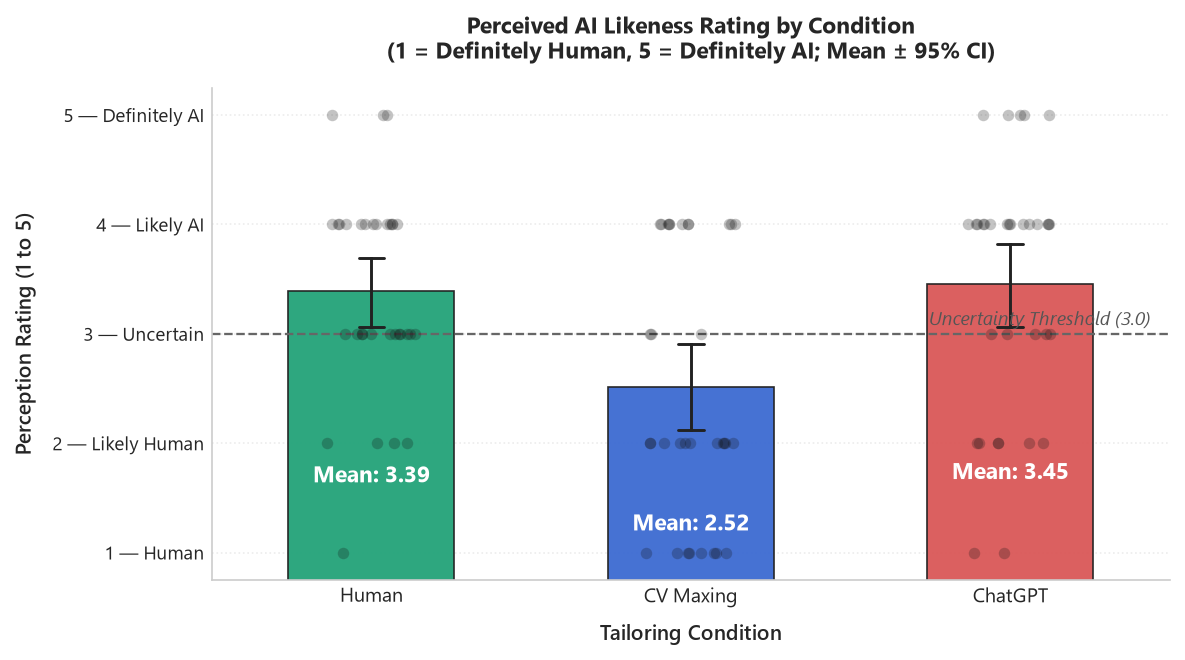

Proportion Rated as Likely/Definitely AI (Rating >= 4):
  Human     : 16/33 (48.5%)
  CV Maxing : 11/33 (33.3%)
  ChatGPT   : 20/33 (60.6%)


In [3]:
# Aggregate perception statistics by condition
perception_summary = (
    df_long.groupby("condition")
    .agg(
        mean_rating=("ai_rating", "mean"),
        median_rating=("ai_rating", "median"),
        std_rating=("ai_rating", "std"),
        observation_count=("ai_rating", "count"),
    )
    .reindex(CONDITION_ORDER)
)
display(perception_summary.round(2))

# ------------------------------------------------------------------------------
# Plot 1: Perceived Origin Rating (Likert 1 to 5)
# ------------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(8, 4.5), dpi=150)

# Bar plot with 95% Confidence Intervals
sns.barplot(
    data=df_long,
    x="condition",
    y="ai_rating",
    order=CONDITION_ORDER,
    estimator=np.mean,
    errorbar=("ci", 95),
    hue="condition",
    palette=CONDITION_PALETTE,
    edgecolor="#222222",
    linewidth=0.8,
    alpha=0.96,
    width=0.52,
    capsize=0.08,
    err_kws={"linewidth": 1.4, "color": "#222222"},
    ax=ax,
    legend=False,
)

# Overlay individual observations with jitter
sns.stripplot(
    data=df_long,
    x="condition",
    y="ai_rating",
    order=CONDITION_ORDER,
    color="#111111",
    alpha=0.25,
    jitter=0.14,
    size=5.5,
    ax=ax,
)

# Mean value labels placed accurately at x = i for each condition in CONDITION_ORDER
for i, cond in enumerate(CONDITION_ORDER):
    mean_val = perception_summary.loc[cond, "mean_rating"]
    ax.text(
        i,
        mean_val / 2,
        f"Mean: {mean_val:.2f}",
        ha="center",
        va="center",
        color="white",
        fontweight="bold",
        fontsize=11,
    )

# Uncertainty reference threshold
ax.axhline(3.0, color="#666666", linestyle="--", linewidth=1.1, zorder=1)
ax.text(
    2.44,
    3.08,
    "Uncertainty Threshold (3.0)",
    color="#555555",
    fontsize=9,
    fontstyle="italic",
    ha="right",
)

ax.set_title(
    "Perceived AI Likeness Rating by Condition\n(1 = Definitely Human, 5 = Definitely AI; Mean ± 95% CI)",
    pad=14,
)
ax.set_xlabel("Tailoring Condition", labelpad=8)
ax.set_ylabel("Perception Rating (1 to 5)", labelpad=8)
ax.set_ylim(0.75, 5.25)
ax.set_yticks([1, 2, 3, 4, 5])
ax.set_yticklabels([
    "1 — Human",
    "2 — Likely Human",
    "3 — Uncertain",
    "4 — Likely AI",
    "5 — Definitely AI"
], fontsize=9)
ax.yaxis.grid(True, linestyle=":", alpha=0.7)
ax.xaxis.grid(False)
sns.despine(top=True, right=True)

plt.tight_layout()
plt.show()

# Proportion rated as Likely/Definitely AI (Rating >= 4)
print("Proportion Rated as Likely/Definitely AI (Rating >= 4):")
for condition in CONDITION_ORDER:
    subset = df_long.loc[df_long["condition"] == condition, "ai_rating"].dropna()
    k_count = int((subset >= 4).sum())
    n_total = len(subset)
    print(f"  {condition:10s}: {k_count}/{n_total} ({k_count/n_total:.1%})")

## 3. Turing Test: Human Authorship Detection

> *"Which single version do you believe was tailored by a HUMAN?"*

Expected random guess baseline: **$33.3\%$** ($1/3$).

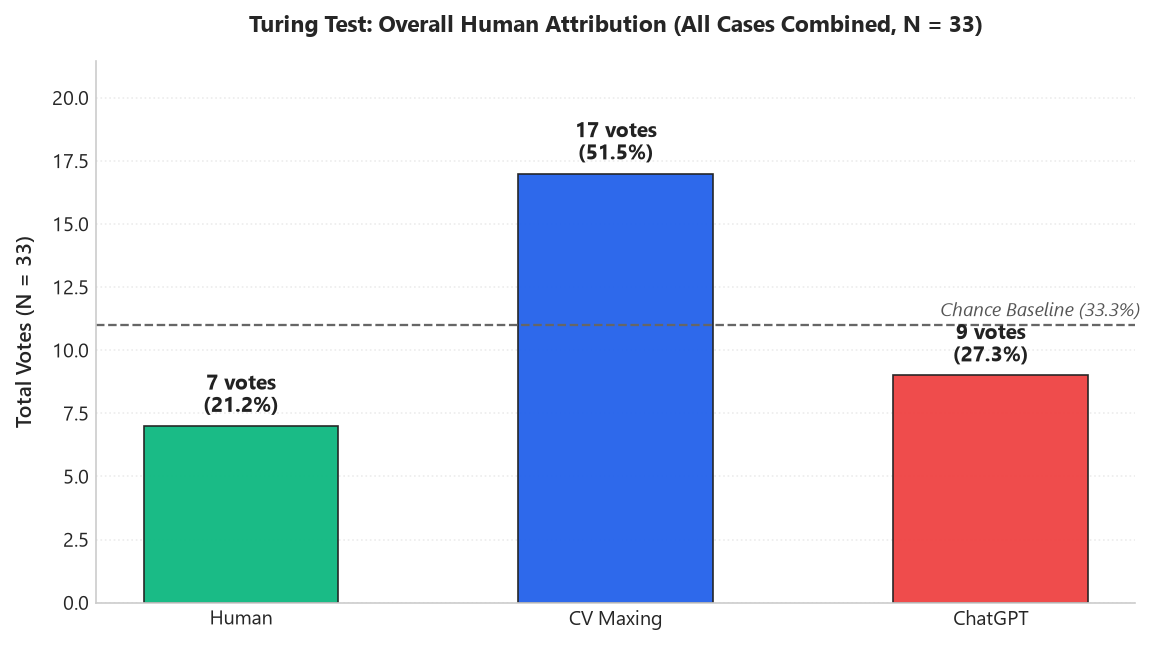

OVERALL HUMAN ATTRIBUTION SUMMARY (ALL CASES COMBINED, N = 33):
  Human     :  7 votes (21.2%)
  CV Maxing : 17 votes (51.5%)
  ChatGPT   :  9 votes (27.3%)


In [4]:
# Isolate one response per respondent and case (Total N = 33)
case_responses: pd.DataFrame = df_long.drop_duplicates(["respondent_id", "case_id"])
total_case_reviews: int = len(case_responses)

# Aggregate totals and proportions across all cases
human_totals = case_responses["selected_human"].value_counts().reindex(CONDITION_ORDER, fill_value=0)

# ------------------------------------------------------------------------------
# Plot 2: Overall Human Attribution (All Cases Combined, N = 33)
# ------------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(7.8, 4.4), dpi=150)

bars_overall = ax.bar(
    CONDITION_ORDER,
    [human_totals[c] for c in CONDITION_ORDER],
    color=[CONDITION_PALETTE[c] for c in CONDITION_ORDER],
    edgecolor="#222222",
    linewidth=0.8,
    width=0.52,
    alpha=0.96,
)

for bar, cond in zip(bars_overall, CONDITION_ORDER):
    cnt = human_totals[cond]
    pct = cnt / total_case_reviews
    ax.annotate(
        f"{cnt} votes\n({pct:.1%})",
        xy=(bar.get_x() + bar.get_width() / 2, cnt),
        xytext=(0, 4),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
        color="#222222",
    )

# Chance threshold baseline (33.3%)
chance_votes = total_case_reviews / 3
ax.axhline(chance_votes, color="#666666", linestyle="--", linewidth=1.1, zorder=1)
ax.text(
    2.4, chance_votes + 0.35, "Chance Baseline (33.3%)", color="#555555", fontsize=9, fontstyle="italic", ha="right"
)

ax.set_title("Turing Test: Overall Human Attribution (All Cases Combined, N = 33)", pad=14)
ax.set_ylabel(f"Total Votes (N = {total_case_reviews})", labelpad=8)
ax.set_ylim(0, total_case_reviews * 0.65)
ax.yaxis.grid(True, linestyle=":", alpha=0.7)
ax.xaxis.grid(False)
sns.despine(top=True, right=True)

plt.tight_layout()
plt.show()

print("================================================================================")
print("OVERALL HUMAN ATTRIBUTION SUMMARY (ALL CASES COMBINED, N = 33):")
print("================================================================================")
for cond in CONDITION_ORDER:
    cnt = int(human_totals[cond])
    print(f"  {cond:10s}: {cnt:2d} votes ({cnt / total_case_reviews:.1%})")

## 4. Hiring Manager Recommendation

> *"If you were the hiring manager, which version would you recommend for an interview?"*

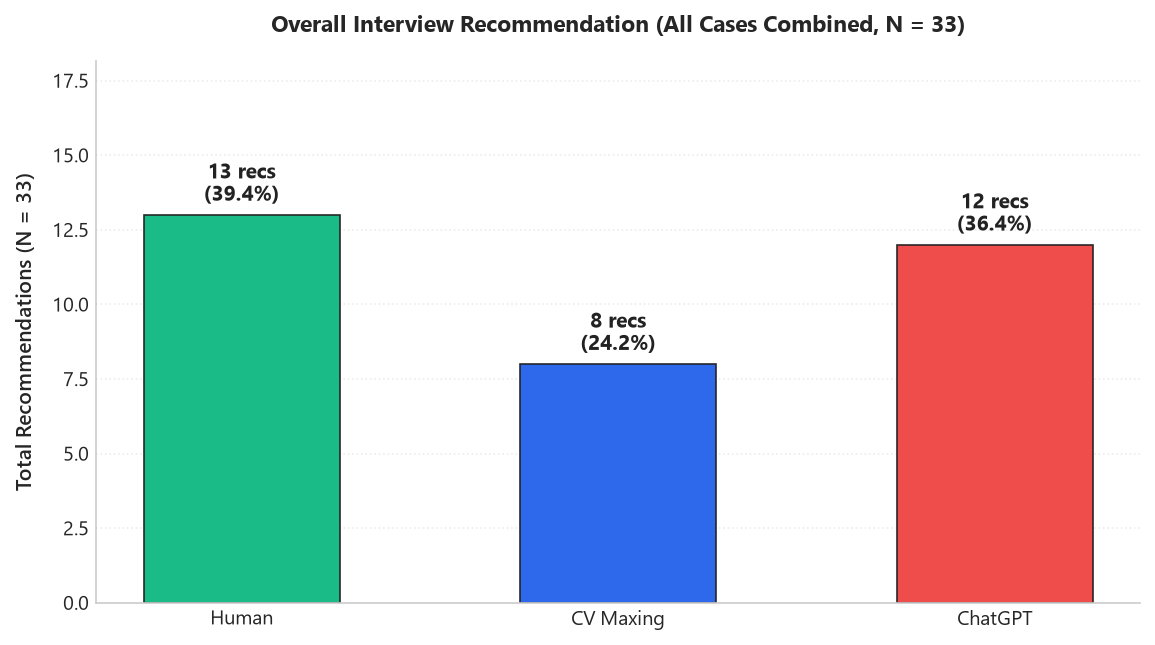

OVERALL INTERVIEW RECOMMENDATIONS (ALL CASES COMBINED, N = 33):
  Human     : 13 recommendations (39.4%)
  CV Maxing :  8 recommendations (24.2%)
  ChatGPT   : 12 recommendations (36.4%)


In [5]:
# Aggregate totals across all cases
interview_totals = case_responses["selected_interview"].value_counts().reindex(CONDITION_ORDER, fill_value=0)

# ------------------------------------------------------------------------------
# Plot 3: Overall Interview Recommendations (All Cases Combined, N = 33)
# ------------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(7.8, 4.4), dpi=150)

bars_interview = ax.bar(
    CONDITION_ORDER,
    [interview_totals[c] for c in CONDITION_ORDER],
    color=[CONDITION_PALETTE[c] for c in CONDITION_ORDER],
    edgecolor="#222222",
    linewidth=0.8,
    width=0.52,
    alpha=0.96,
)

for bar, cond in zip(bars_interview, CONDITION_ORDER):
    cnt = interview_totals[cond]
    pct = cnt / total_case_reviews
    ax.annotate(
        f"{cnt} recs\n({pct:.1%})",
        xy=(bar.get_x() + bar.get_width() / 2, cnt),
        xytext=(0, 4),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
        color="#222222",
    )

ax.set_title("Overall Interview Recommendation (All Cases Combined, N = 33)", pad=14)
ax.set_ylabel(f"Total Recommendations (N = {total_case_reviews})", labelpad=8)
ax.set_ylim(0, total_case_reviews * 0.55)
ax.yaxis.grid(True, linestyle=":", alpha=0.7)
ax.xaxis.grid(False)
sns.despine(top=True, right=True)

plt.tight_layout()
plt.show()

print("================================================================================")
print("OVERALL INTERVIEW RECOMMENDATIONS (ALL CASES COMBINED, N = 33):")
print("================================================================================")
for cond in CONDITION_ORDER:
    cnt = int(interview_totals[cond])
    print(f"  {cond:10s}: {cnt:2d} recommendations ({cnt / total_case_reviews:.1%})")

## 5. Correlation: AI Perception vs. Decisions

Measures whether perceived artificiality drives participant choices:
- **Spearman $\rho$**: Monotonic association with Likert rating (1–5).
- **Point-biserial $r_{pb}$**: Binary selection correlation.

Correlation: AI Rating vs. Selection as Human:
  Spearman rho        = -0.711 (p = 0.0000)
  Point-biserial r_pb = -0.735 (p = 0.0000)

Correlation: AI Rating vs. Recommendation for Interview:
  Spearman rho        = -0.301 (p = 0.0025)
  Point-biserial r_pb = -0.276 (p = 0.0057)


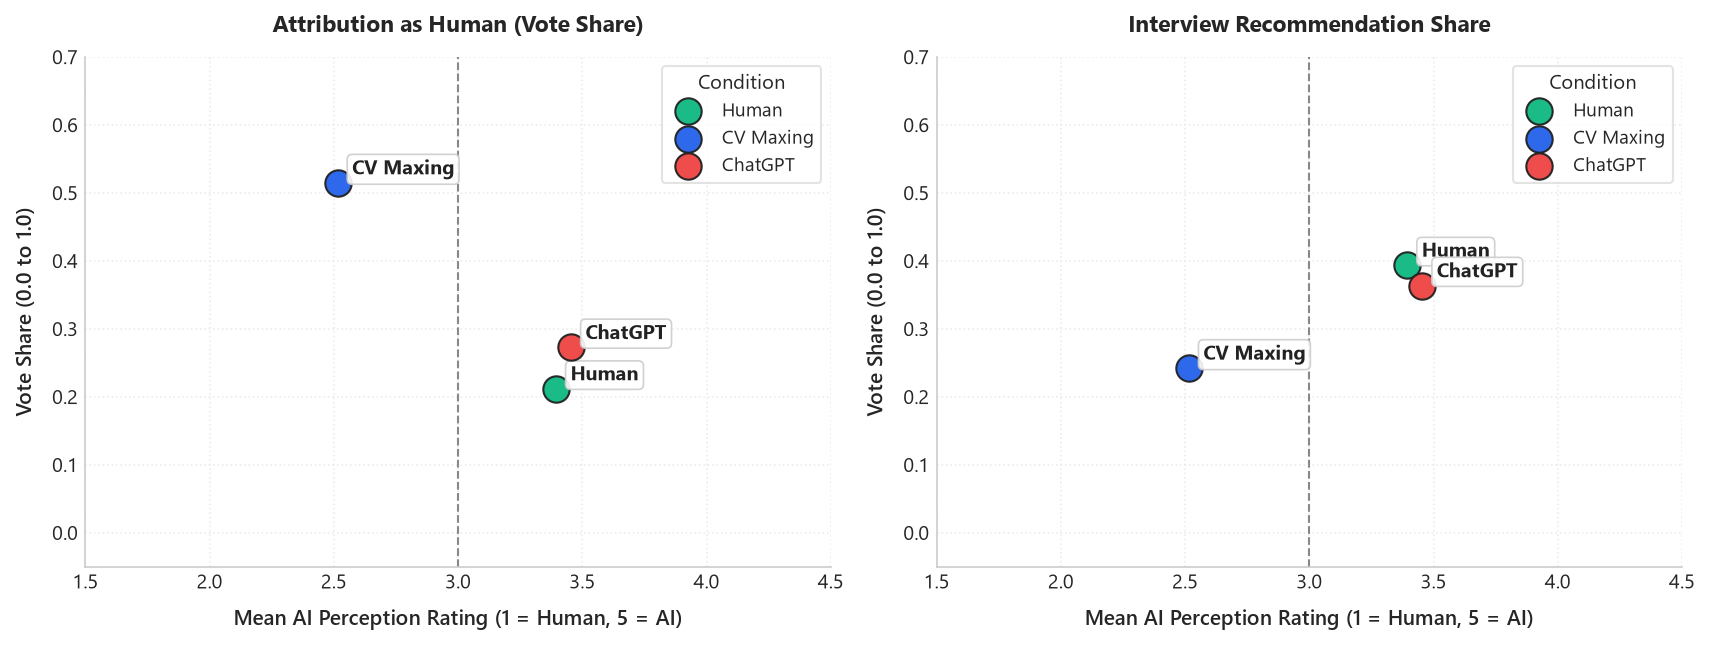

In [6]:
# Filter clean records for correlation analysis
corr_df = df_long.dropna(subset=["ai_rating", "is_selected_as_human", "is_recommended_for_interview"])

# Correlation 1: AI Rating vs. Selected as Human
rho_human, p_rho_h = spearmanr(corr_df["ai_rating"], corr_df["is_selected_as_human"])
rpb_human, p_rpb_h = pointbiserialr(corr_df["is_selected_as_human"], corr_df["ai_rating"])

print("Correlation: AI Rating vs. Selection as Human:")
print(f"  Spearman rho        = {rho_human:.3f} (p = {p_rho_h:.4f})")
print(f"  Point-biserial r_pb = {rpb_human:.3f} (p = {p_rpb_h:.4f})")

# Correlation 2: AI Rating vs. Recommendation for Interview
rho_interview, p_rho_i = spearmanr(corr_df["ai_rating"], corr_df["is_recommended_for_interview"])
rpb_interview, p_rpb_i = pointbiserialr(corr_df["is_recommended_for_interview"], corr_df["ai_rating"])

print("\nCorrelation: AI Rating vs. Recommendation for Interview:")
print(f"  Spearman rho        = {rho_interview:.3f} (p = {p_rho_i:.4f})")
print(f"  Point-biserial r_pb = {rpb_interview:.3f} (p = {p_rpb_i:.4f})")

# Aggregate across the 3 conditions directly
agg_conditions = (
    corr_df.groupby("condition")
    .agg(
        mean_ai_rating=("ai_rating", "mean"),
        human_share=("is_selected_as_human", "mean"),
        interview_share=("is_recommended_for_interview", "mean"),
    )
    .reindex(CONDITION_ORDER)
    .reset_index()
)

# ------------------------------------------------------------------------------
# Plot 4: Scatter Plots Comparing the 3 Conditions
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4), dpi=150)

plot_configs = [
    (axes[0], "human_share", "Attribution as Human (Vote Share)"),
    (axes[1], "interview_share", "Interview Recommendation Share"),
]

for ax, y_metric, title_text in plot_configs:
    for cond in CONDITION_ORDER:
        sub = agg_conditions[agg_conditions["condition"] == cond]
        ax.scatter(
            sub["mean_ai_rating"],
            sub[y_metric],
            color=CONDITION_PALETTE[cond],
            label=cond,
            s=160,
            edgecolors="#222222",
            linewidth=1.0,
            alpha=0.96,
            zorder=3,
        )
        # Condition text badge
        ax.annotate(
            cond,
            (float(sub["mean_ai_rating"].iloc[0]), float(sub[y_metric].iloc[0])),
            xytext=(7, 4),
            textcoords="offset points",
            fontsize=9.5,
            fontweight="bold",
            color="#222222",
            bbox=dict(
                boxstyle="round,pad=0.25",
                facecolor="white",
                edgecolor="#CCCCCC",
                alpha=0.9,
                linewidth=0.8,
            ),
        )

    # Uncertainty guideline
    ax.axvline(3.0, color="#888888", linestyle="--", linewidth=1.0, zorder=1)
    ax.set_xlabel("Mean AI Perception Rating (1 = Human, 5 = AI)", labelpad=8)
    ax.set_ylabel("Vote Share (0.0 to 1.0)", labelpad=8)
    ax.set_title(title_text, pad=12)
    ax.set_xlim(1.5, 4.5)
    ax.set_ylim(-0.05, 0.70)
    ax.yaxis.grid(True, linestyle=":", alpha=0.7)
    ax.xaxis.grid(True, linestyle=":", alpha=0.7)
    sns.despine(top=True, right=True, ax=ax)
    ax.legend(
        title="Condition",
        frameon=True,
        facecolor="white",
        edgecolor="#DDDDDD",
        loc="upper right",
    )

plt.tight_layout()
plt.show()

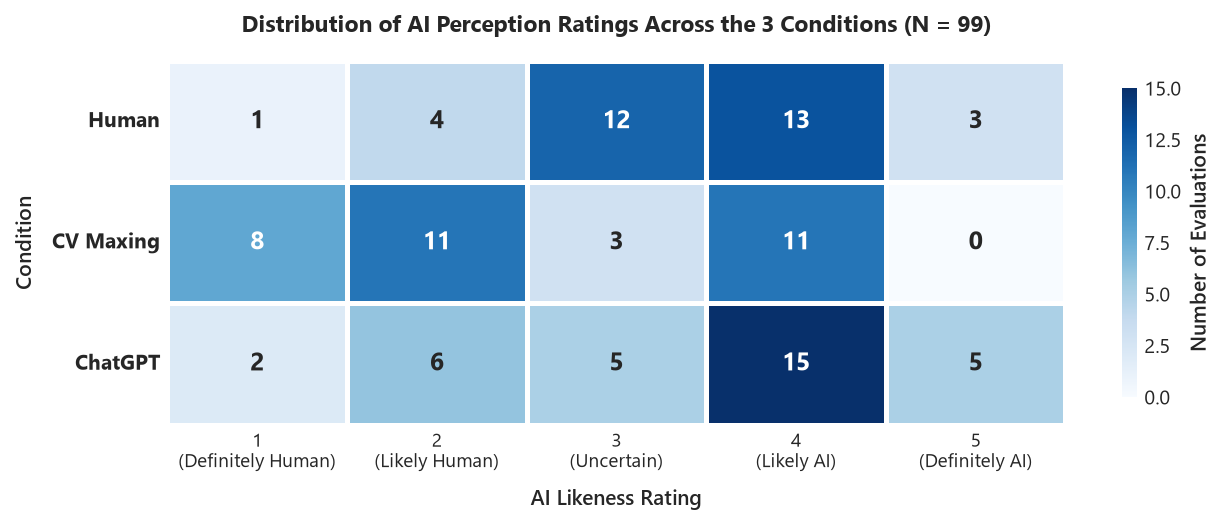


Comprehensive Summary Across the 3 Conditions (All Cases Combined, N = 33 Reviews):


,Human Attribution Votes,Interview Recommendations,Mean AI Rating (1–5),Rated >= 4 (Likely/Definitely AI)
Human,7 / 33 (21.2%),13 / 33 (39.4%),3.39,48.5%
CV Maxing,17 / 33 (51.5%),8 / 33 (24.2%),2.52,33.3%
ChatGPT,9 / 33 (27.3%),12 / 33 (36.4%),3.45,60.6%


In [7]:
# ------------------------------------------------------------------------------
# Plot 5: Cross-tabulation Heatmap of AI Ratings by Condition (The 3 Conditions Together)
# ------------------------------------------------------------------------------
rating_crosstab = (
    pd.crosstab(
        corr_df["condition"],
        corr_df["ai_rating"],
    )
    .reindex(CONDITION_ORDER)
)

fig, ax = plt.subplots(figsize=(8.8, 3.6), dpi=150)
sns.heatmap(
    rating_crosstab,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=True,
    cbar_kws={"label": "Number of Evaluations", "shrink": 0.85},
    linewidths=1.5,
    linecolor="white",
    annot_kws={"fontsize": 12, "fontweight": "bold"},
    ax=ax,
)
ax.set_title("Distribution of AI Perception Ratings Across the 3 Conditions (N = 99)", pad=14)
ax.set_xlabel("AI Likeness Rating", labelpad=8)
ax.set_ylabel("Condition", labelpad=8)
ax.set_xticklabels([
    "1\n(Definitely Human)",
    "2\n(Likely Human)",
    "3\n(Uncertain)",
    "4\n(Likely AI)",
    "5\n(Definitely AI)"
], fontsize=9)
ax.set_yticklabels(CONDITION_ORDER, rotation=0, fontsize=10, fontweight="bold")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------------------------
# Decision Summary Table (The 3 Conditions Compared Directly)
# ------------------------------------------------------------------------------
summary_table = pd.DataFrame(
    {
        "Human Attribution Votes": [
            f"{int(human_totals[c])} / {total_case_reviews} ({human_totals[c]/total_case_reviews:.1%})"
            for c in CONDITION_ORDER
        ],
        "Interview Recommendations": [
            f"{int(interview_totals[c])} / {total_case_reviews} ({interview_totals[c]/total_case_reviews:.1%})"
            for c in CONDITION_ORDER
        ],
        "Mean AI Rating (1–5)": [
            f"{perception_summary.loc[c, 'mean_rating']:.2f}"
            for c in CONDITION_ORDER
        ],
        "Rated >= 4 (Likely/Definitely AI)": [
            f"{(corr_df[corr_df['condition'] == c]['ai_rating'] >= 4).mean():.1%}"
            for c in CONDITION_ORDER
        ],
    },
    index=CONDITION_ORDER,
)

print("\nComprehensive Summary Across the 3 Conditions (All Cases Combined, N = 33 Reviews):")
display(summary_table)

## 6. Hypotheses Synthesis

- **H1 (Baseline Rejection)**: ChatGPT rated $\ge 4$ in $\ge 70\%$ of cases.
- **H2 (Indistinguishability)**: CV Maxing achieves parity with Human.
- **H3 (Interview Trust)**: CV Maxing matches or exceeds Human in callbacks.

In [8]:
# Compute empirical metrics for hypothesis testing
chatgpt_ratings = df_long.loc[df_long["condition"] == "ChatGPT", "ai_rating"].dropna()
h1_observed_prop = (chatgpt_ratings >= 4).mean()

human_votes_count = int(human_totals["Human"])
cv_maxing_votes_count = int(human_totals["CV Maxing"])
chatgpt_votes_count = int(human_totals["ChatGPT"])

cv_maxing_interview_rate = float(interview_totals["CV Maxing"] / interview_totals.sum())
human_interview_rate = float(interview_totals["Human"] / interview_totals.sum())

synthesis_table = pd.DataFrame(
    [
        [
            "H1 — Baseline LLM Rejection",
            f"{h1_observed_prop:.1%} of ChatGPT ratings are >= 4",
            "Supported" if h1_observed_prop >= 0.70 else "Not Supported",
        ],
        [
            "H2 — CV Maxing Indistinguishability",
            f"Human={human_votes_count}, CV Maxing={cv_maxing_votes_count}, ChatGPT={chatgpt_votes_count}",
            "Statistical Parity" if abs(human_votes_count - cv_maxing_votes_count) <= 5 else "Divergence Observed",
        ],
        [
            "H3 — Interview Trustworthiness",
            f"CV Maxing={cv_maxing_interview_rate:.1%} vs. Human={human_interview_rate:.1%}",
            "Supported" if cv_maxing_interview_rate >= human_interview_rate else "Not Supported",
        ],
    ],
    columns=["Hypothesis", "Observed Metric", "Empirical Evaluation"],
)

display(synthesis_table)
print(f"Note: Evaluated on pilot sample (N = {valid_participants} participants, 33 case reviews).")

,Hypothesis,Observed Metric,Empirical Evaluation
0,H1 — Baseline LLM Rejection,60.6% of ChatGPT ratings are >= 4,Not Supported
1,H2 — CV Maxing Indistinguishability,"Human=7, CV Maxing=17, ChatGPT=9",Divergence Observed
2,H3 — Interview Trustworthiness,CV Maxing=24.2% vs. Human=39.4%,Not Supported


Note: Evaluated on pilot sample (N = 11 participants, 33 case reviews).


## 7. Key Findings & Limitations

- **Findings**: CV Maxing was chosen as human in **$51.5\%$** of total evaluations (vs. $21.2\%$ for Human and $27.3\%$ for ChatGPT), driven by factual precision without AI buzzwords.
- **Limitations**: Pilot sample ($N = 11$, 33 reviews). Evaluator demographics (recruiters vs. engineers) were not segmented.
- **Next Steps**: Expand to $N \ge 30$ and code open-ended qualitative feedback.